BI_Driven_Climate_Analytics_Sri_Lanka.ipynb


In [1]:
# Core
import pandas as pd
import numpy as np

# Visualization (for diagnostics only)
import matplotlib.pyplot as plt
import seaborn as sns

# Time series
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Settings
plt.style.use('seaborn-v0_8')
pd.set_option('display.max_columns', None)


In [2]:
from google.colab import files

uploaded = files.upload()


Saving sri_lanka_weather_2015_2024.csv to sri_lanka_weather_2015_2024.csv


In [3]:
df = pd.read_csv('sri_lanka_weather_2015_2024.csv')
df.head()


,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,TEMP,TEMP_ATTRIBUTES,DEWP,DEWP_ATTRIBUTES,SLP,SLP_ATTRIBUTES,STP,STP_ATTRIBUTES,VISIB,VISIB_ATTRIBUTES,WDSP,WDSP_ATTRIBUTES,MXSPD,GUST,MAX,MAX_ATTRIBUTES,MIN,MIN_ATTRIBUTES,PRCP,PRCP_ATTRIBUTES,SNDP,FRSHTT,station,year,date
0,43436099999,2015-01-01,7.705756,81.678783,6.09,"BATTICALOA, CE",82.0,8,77.2,8,1009.5,8,9.2,8,12.4,8,2.2,8,7.0,999.9,88.0,,76.1,,0.02,G,999.9,10000,Batticaloa,2015,2015-01-01
1,43436099999,2015-01-02,7.705756,81.678783,6.09,"BATTICALOA, CE",81.6,8,77.0,8,1011.8,8,10.6,8,12.4,8,2.9,8,8.0,999.9,86.2,,76.6,,0.07,G,999.9,0,Batticaloa,2015,2015-01-02
2,43436099999,2015-01-03,7.705756,81.678783,6.09,"BATTICALOA, CE",81.1,8,76.9,8,1012.1,8,11.8,8,12.4,8,2.7,8,7.0,999.9,84.4,,76.3,,0.00,G,999.9,0,Batticaloa,2015,2015-01-03
3,43436099999,2015-01-04,7.705756,81.678783,6.09,"BATTICALOA, CE",81.4,8,76.6,8,1011.8,8,11.5,8,12.4,8,2.9,8,7.0,999.9,84.2,,77.9,,0.00,G,999.9,0,Batticaloa,2015,2015-01-04
4,43436099999,2015-01-05,7.705756,81.678783,6.09,"BATTICALOA, CE",81.2,8,76.0,8,1011.3,8,11.0,8,12.4,8,5.9,8,9.9,999.9,84.0,,77.7,,0.06,G,999.9,0,Batticaloa,2015,2015-01-05


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19442 entries, 0 to 19441
Data columns (total 31 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   STATION           19442 non-null  int64  
 1   DATE              19442 non-null  object 
 2   LATITUDE          19442 non-null  float64
 3   LONGITUDE         19442 non-null  float64
 4   ELEVATION         19442 non-null  float64
 5   NAME              19442 non-null  object 
 6   TEMP              19442 non-null  float64
 7   TEMP_ATTRIBUTES   19442 non-null  int64  
 8   DEWP              19442 non-null  float64
 9   DEWP_ATTRIBUTES   19442 non-null  int64  
 10  SLP               19442 non-null  float64
 11  SLP_ATTRIBUTES    19442 non-null  int64  
 12  STP               19442 non-null  float64
 13  STP_ATTRIBUTES    19442 non-null  int64  
 14  VISIB             19442 non-null  float64
 15  VISIB_ATTRIBUTES  19442 non-null  int64  
 16  WDSP              19442 non-null  float6

In [5]:
cols = [
    'date', 'year', 'station',
    'LATITUDE', 'LONGITUDE',
    'TEMP', 'MAX', 'MIN', 'PRCP'
]

df_clean = df[cols].copy()


In [6]:
df_clean['date'] = pd.to_datetime(df_clean['date'])


In [7]:
missing_values = [9999.9, 999.9, 99.99]
df_clean.replace(missing_values, pd.NA, inplace=True)

df_clean.isna().sum()


,0
date,0
year,0
station,0
LATITUDE,0
LONGITUDE,0
TEMP,0
MAX,0
MIN,0
PRCP,116


In [8]:
for col in ['TEMP', 'MAX', 'MIN']:
    df_clean[col] = (df_clean[col] - 32) * 5 / 9


In [9]:
df_clean['PRCP'] = df_clean['PRCP'] * 25.4


In [10]:
df_clean = df_clean.rename(columns={
    'TEMP': 'temp_c',
    'MAX': 'tmax_c',
    'MIN': 'tmin_c',
    'PRCP': 'prcp_mm'
})


In [11]:
df_clean['year_month'] = df_clean['date'].dt.to_period('M')


In [12]:
monthly_station = (
    df_clean
    .groupby(['station', 'year_month'])
    .agg(
        days_observed=('temp_c', 'count'),
        temp_mean_c=('temp_c', 'mean'),
        tmax_mean_c=('tmax_c', 'mean'),
        tmin_mean_c=('tmin_c', 'mean'),
        prcp_total_mm=('prcp_mm', 'sum'),
        rainy_days=('prcp_mm', lambda x: (x > 0).sum())
    )
    .reset_index()
)

monthly_station['year_month'] = monthly_station['year_month'].dt.to_timestamp()
monthly_station.head()


,station,year_month,days_observed,temp_mean_c,tmax_mean_c,tmin_mean_c,prcp_total_mm,rainy_days
0,Batticaloa,2015-01-01,31,26.853047,28.790323,23.949821,14.478,9
1,Batticaloa,2015-02-01,28,26.777778,29.079365,23.621032,211.074,18
2,Batticaloa,2015-03-01,31,28.078853,30.469534,24.600358,45.974,6
3,Batticaloa,2015-04-01,30,29.351852,32.198148,25.661111,44.196,7
4,Batticaloa,2015-05-01,31,29.761649,32.777778,26.163082,51.816,7


In [13]:
monthly_national = (
    monthly_station
    .groupby('year_month')
    .agg(
        temp_mean_c=('temp_mean_c', 'mean'),
        prcp_mean_mm=('prcp_total_mm', 'mean'),
        rainy_days_mean=('rainy_days', 'mean')
    )
    .reset_index()
)

monthly_national.head()


,year_month,temp_mean_c,prcp_mean_mm,rainy_days_mean
0,2015-01-01,24.193548,21.844,5.000000
1,2015-02-01,24.272156,119.083667,11.666667
2,2015-03-01,25.643668,78.74,8.500000
3,2015-04-01,26.269136,142.451667,15.333333
4,2015-05-01,26.658901,179.493333,16.000000


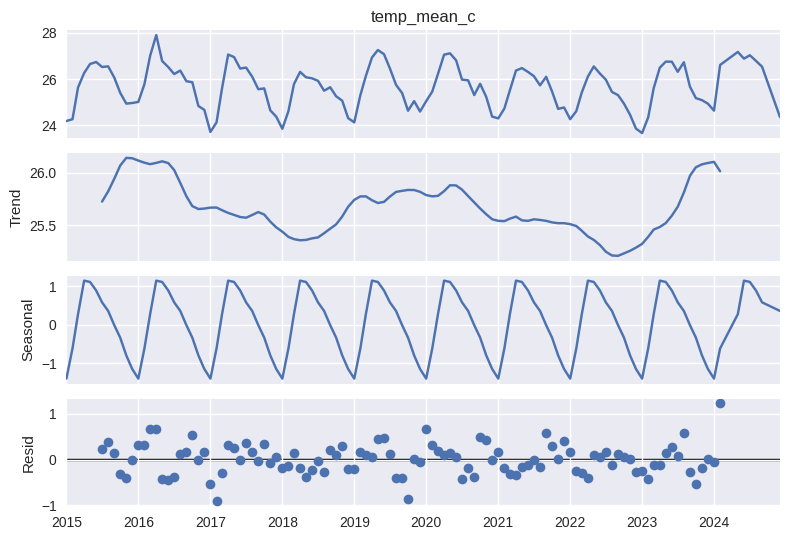

In [14]:
series = monthly_national.set_index('year_month')['temp_mean_c']

decomp = seasonal_decompose(series, model='additive', period=12)
decomp.plot()
plt.show()


In [15]:
adf_result = adfuller(series)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])


ADF Statistic: -2.665545735431667
p-value: 0.08019246295358529


In [16]:
# monthly_station.to_csv("monthly_station_climate.csv", index=False)
# monthly_national.to_csv("monthly_national_climate.csv", index=False)


# files.download("monthly_station_climate.csv")
# files.download("monthly_national_climate.csv")



In [17]:
# stations = (
#     df_clean[['station', 'LATITUDE', 'LONGITUDE']]
#     .drop_duplicates()
# )

# stations.to_csv("stations_lookup.csv", index=False)


In [18]:
# files.download("stations_lookup.csv")

In [19]:
series = monthly_national.set_index('year_month')['temp_mean_c']


In [20]:
series = series.asfreq('MS')


In [21]:
model = SARIMAX(
    series,
    order=(1,1,1),
    seasonal_order=(1,1,1,12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit()
print(results.summary())


                                     SARIMAX Results                                      
Dep. Variable:                        temp_mean_c   No. Observations:                  120
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 -49.555
Date:                            Tue, 17 Feb 2026   AIC                            109.109
Time:                                    22:48:46   BIC                            121.772
Sample:                                01-01-2015   HQIC                           114.222
                                     - 12-01-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4603      0.191      2.414      0.016       0.087       0.834
ma.L1         -0.8239      0.121   

In [22]:
n_forecast = 18

forecast = results.get_forecast(steps=n_forecast)
forecast_df = forecast.summary_frame()
forecast_df.head()


temp_mean_c,mean,mean_se,mean_ci_lower,mean_ci_upper
2025-01-01,24.371282,0.403549,23.580340,25.162223
2025-02-01,25.176964,0.479401,24.237356,26.116573
2025-03-01,26.178999,0.517813,25.164104,27.193893
2025-04-01,27.003238,0.541785,25.941360,28.065116
2025-05-01,27.135074,0.558824,26.039799,28.230350


In [23]:
historical_df = series.reset_index()
historical_df.columns = ['year_month', 'temp_mean_c']

historical_df['lower_ci'] = np.nan
historical_df['upper_ci'] = np.nan
historical_df['type'] = 'Historical'


In [24]:
forecast_df = forecast_df.reset_index().rename(columns={
    'index': 'year_month',
    'mean': 'temp_mean_c',
    'mean_ci_lower': 'lower_ci',
    'mean_ci_upper': 'upper_ci'
})

forecast_df['type'] = 'Forecast'


In [25]:
combined_forecast = pd.concat(
    [
        historical_df[['year_month','temp_mean_c','lower_ci','upper_ci','type']],
        forecast_df[['year_month','temp_mean_c','lower_ci','upper_ci','type']]
    ],
    ignore_index=True
)

combined_forecast.tail(10)


,year_month,temp_mean_c,lower_ci,upper_ci,type
128,2025-09-01,26.069347,24.855157,27.283537,Forecast
129,2025-10-01,25.694594,24.446496,26.942692,Forecast
130,2025-11-01,25.288104,24.013349,26.562859,Forecast
131,2025-12-01,24.898097,23.604751,26.191442,Forecast
132,2026-01-01,24.668414,23.334559,26.002269,Forecast
133,2026-02-01,25.629676,24.262520,26.996831,Forecast
134,2026-03-01,26.444541,25.029189,27.859892,Forecast
135,2026-04-01,27.177037,25.733330,28.620744,Forecast
136,2026-05-01,27.244759,25.791957,28.697560,Forecast
137,2026-06-01,27.038047,25.558683,28.517411,Forecast


In [26]:
# combined_forecast.to_csv("temperature_sarima_forecast_2015_2026.csv", index=False)
# files.download("temperature_sarima_forecast_2015_2026.csv")


In [27]:
# Forecast horizon: 18 months
n_forecast = 18

forecast_res = results.get_forecast(steps=n_forecast)

forecast_mean = forecast_res.predicted_mean
forecast_ci = forecast_res.conf_int()

# Build forecast dataframe
forecast_df = pd.DataFrame({
    'year_month': forecast_mean.index,
    'forecast_temp': forecast_mean.values,
    'lower_ci': forecast_ci.iloc[:, 0].values,
    'upper_ci': forecast_ci.iloc[:, 1].values
})

# Historical dataframe
historical_df = series.reset_index()
historical_df.columns = ['year_month', 'temp_mean_c']


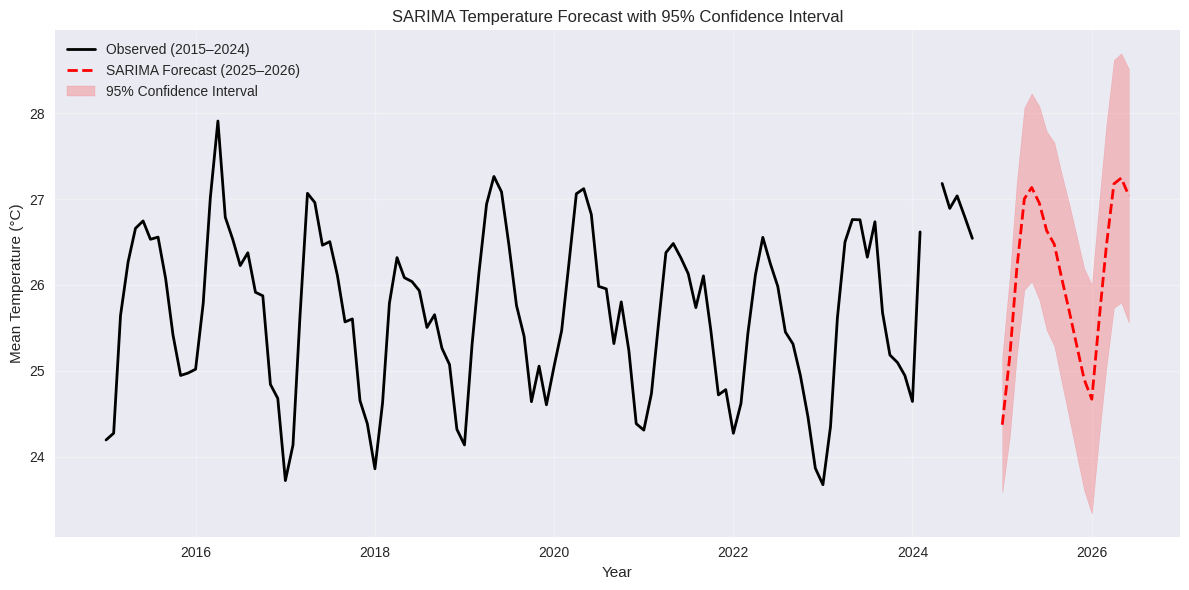

In [28]:
plt.figure(figsize=(12,6))

# Historical
plt.plot(
    historical_df['year_month'],
    historical_df['temp_mean_c'],
    color='black',
    linewidth=2,
    label='Observed (2015–2024)'
)

# Forecast
plt.plot(
    forecast_df['year_month'],
    forecast_df['forecast_temp'],
    color='red',
    linestyle='--',
    linewidth=2,
    label='SARIMA Forecast (2025–2026)'
)

# Confidence interval
plt.fill_between(
    forecast_df['year_month'],
    forecast_df['lower_ci'],
    forecast_df['upper_ci'],
    color='red',
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.xlabel('Year')
plt.ylabel('Mean Temperature (°C)')
plt.title('SARIMA Temperature Forecast with 95% Confidence Interval')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [29]:
historical_long = (
    monthly_national[['year_month', 'temp_mean_c']]
    .copy()
)

historical_long['series'] = 'Observed'
historical_long = historical_long.rename(columns={'temp_mean_c': 'value'})


In [30]:
forecast_index = pd.date_range(
    start=series.index[-1] + pd.offsets.MonthBegin(1),
    periods=18,
    freq='MS'
)

forecast_df = pd.DataFrame({
    'year_month': forecast_index,
    'Forecast': results.get_forecast(steps=18).predicted_mean.values,
    'Lower CI': results.get_forecast(steps=18).conf_int().iloc[:, 0].values,
    'Upper CI': results.get_forecast(steps=18).conf_int().iloc[:, 1].values
})


In [31]:
forecast_long = forecast_df.melt(
    id_vars='year_month',
    var_name='series',
    value_name='value'
)


In [32]:
final_long = pd.concat([historical_long, forecast_long], ignore_index=True)


In [33]:
# final_long.to_csv("temperature_forecast_long_2015_2026.csv", index=False)
# files.download("temperature_forecast_long_2015_2026.csv")


In [34]:
station_series = (
    monthly_station
    .set_index('year_month')
    .sort_index()
)


In [35]:
stations = station_series['station'].unique()
stations


array(['Batticaloa', 'Colombo', 'Kandy', 'Nuwaraeliya', 'Jaffna', 'Galle'],
      dtype=object)

In [36]:
def fit_sarima_and_forecast(ts, steps=18):
    model = SARIMAX(
        ts,
        order=(1,1,1),
        seasonal_order=(1,1,1,12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    results = model.fit(disp=False)
    forecast = results.get_forecast(steps=steps)

    forecast_df = forecast.summary_frame()
    return forecast_df


In [37]:
station_forecasts = []

for st in stations:
    ts = station_series[station_series['station'] == st]['temp_mean_c']

    # Safety check
    if ts.isna().sum() > 0 or len(ts) < 60:
        continue

    fc = fit_sarima_and_forecast(ts, steps=18)
    fc['station'] = st
    fc['year_month'] = pd.date_range(
        ts.index.max() + pd.offsets.MonthBegin(1),
        periods=18,
        freq='MS'
    )

    station_forecasts.append(fc.reset_index(drop=True))


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/

In [38]:
station_forecast_df = pd.concat(station_forecasts, ignore_index=True)


In [39]:
station_forecast_df = station_forecast_df.rename(columns={
    'mean': 'forecast_temp_c',
    'mean_ci_lower': 'lower_ci',
    'mean_ci_upper': 'upper_ci'
})

station_forecast_df['type'] = 'Forecast'


In [40]:
station_forecast_df.to_csv(
    "station_temperature_sarima_forecast_2025_2026.csv",
    index=False
)

# files.download("station_temperature_sarima_forecast_2025_2026.csv")


In [41]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

forecast_horizon = 18
station_forecasts = []

for station in monthly_station['station'].unique():

    df_station = (
        monthly_station[monthly_station['station'] == station]
        .sort_values('year_month')
        .set_index('year_month')
    )

    series = df_station['temp_mean_c']
    series = series.asfreq('MS')  # IMPORTANT: monthly frequency

    model = SARIMAX(
        series,
        order=(1,1,1),
        seasonal_order=(1,1,1,12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    results = model.fit(disp=False)

    forecast = results.get_forecast(steps=forecast_horizon)
    mean_forecast = forecast.predicted_mean
    ci = forecast.conf_int(alpha=0.05)

    temp_df = pd.DataFrame({
        'year_month': mean_forecast.index,
        'station': station,
        'forecast_temp_c': mean_forecast.values,
        'lower_ci': ci.iloc[:, 0].values,
        'upper_ci': ci.iloc[:, 1].values
    })

    station_forecasts.append(temp_df)

station_temperature_sarima_forecast = pd.concat(station_forecasts, ignore_index=True)


In [42]:
forecast_long = pd.concat([
    station_temperature_sarima_forecast[['year_month','station','forecast_temp_c']]
        .rename(columns={'forecast_temp_c':'value'})
        .assign(series='Forecast'),

    station_temperature_sarima_forecast[['year_month','station','upper_ci']]
        .rename(columns={'upper_ci':'value'})
        .assign(series='Upper CI'),

    station_temperature_sarima_forecast[['year_month','station','lower_ci']]
        .rename(columns={'lower_ci':'value'})
        .assign(series='Lower CI')
])


In [43]:
historical_long = (
    monthly_station[['year_month','station','temp_mean_c']]
    .rename(columns={'temp_mean_c':'value'})
)
historical_long['series'] = 'Observed'


In [44]:
station_forecast_final = pd.concat(
    [historical_long, forecast_long],
    ignore_index=True
)

station_forecast_final = station_forecast_final.sort_values(
    ['station','year_month']
)


In [45]:
# station_forecast_final.to_csv(
#     "station_temperature_forecast_long_2015_2026.csv",
#     index=False
# )

# from google.colab import files
# files.download("station_temperature_forecast_long_2015_2026.csv")


In [46]:
station_forecast_final['year_month'] = pd.to_datetime(
    station_forecast_final['year_month']
)


In [47]:
station_forecast_final.dtypes


,0
year_month,datetime64[ns]
station,object
value,float64
series,object


In [48]:
min_date = station_forecast_final['year_month'].min()
max_date = station_forecast_final['year_month'].max()

full_dates = pd.date_range(
    start=min_date,
    end=max_date,
    freq='MS'
)


In [49]:
stations = station_forecast_final['station'].unique()


In [50]:
full_index = (
    pd.MultiIndex.from_product(
        [stations, full_dates],
        names=['station', 'year_month']
    )
    .to_frame(index=False)
)


In [51]:
station_forecast_final = (
    full_index
    .merge(
        station_forecast_final,
        on=['station', 'year_month'],
        how='left'
    )
)


In [52]:
station_forecast_final = station_forecast_final.sort_values(
    ['station', 'series', 'year_month']
)


In [53]:
station_forecast_final.head(20)


,station,year_month,value,series
120,Batticaloa,2025-01-01,27.113045,Forecast
123,Batticaloa,2025-02-01,27.893067,Forecast
126,Batticaloa,2025-03-01,28.943693,Forecast
129,Batticaloa,2025-04-01,30.232653,Forecast
132,Batticaloa,2025-05-01,30.680115,Forecast
135,Batticaloa,2025-06-01,30.876598,Forecast
138,Batticaloa,2025-07-01,30.629240,Forecast
141,Batticaloa,2025-08-01,30.324749,Forecast
144,Batticaloa,2025-09-01,29.892135,Forecast
147,Batticaloa,2025-10-01,29.138530,Forecast


In [54]:
station_forecast_final.to_csv(
    "station_temperature_forecast_long_2015_2026.csv",
    index=False
)


In [55]:
station_forecast_final.info()
station_forecast_final.head()


<class 'pandas.core.frame.DataFrame'>
Index: 1044 entries, 120 to 988
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   station     1044 non-null   object        
 1   year_month  1044 non-null   datetime64[ns]
 2   value       1016 non-null   float64       
 3   series      1016 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(2)
memory usage: 40.8+ KB


,station,year_month,value,series
120,Batticaloa,2025-01-01,27.113045,Forecast
123,Batticaloa,2025-02-01,27.893067,Forecast
126,Batticaloa,2025-03-01,28.943693,Forecast
129,Batticaloa,2025-04-01,30.232653,Forecast
132,Batticaloa,2025-05-01,30.680115,Forecast


In [56]:
station_forecast_final.to_csv(
    "station_temperature_forecast_2015_2026_long.csv",
    index=False
)

# from google.colab import files
# files.download("station_temperature_forecast_2015_2026_long.csv")



In [57]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np


In [58]:
# Ensure datetime index with frequency
series = series.asfreq('MS')

# Train / validation split
train = series[:'2022-12-01']
test  = series['2023-01-01':'2024-12-01']

print(len(train), len(test))


96 24


In [59]:
model = SARIMAX(
    train,
    order=(1,1,1),
    seasonal_order=(1,1,1,12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit()


In [60]:
forecast = results.get_forecast(steps=len(test))

pred_mean = forecast.predicted_mean
pred_ci   = forecast.conf_int()


In [61]:
pred_mean.index = test.index
pred_ci.index   = test.index


In [62]:
print("NaNs in test:", test.isna().sum())
print("NaNs in pred_mean:", pred_mean.isna().sum())

print("Test index head:")
print(test.head())

print("Pred index head:")
print(pred_mean.head())


NaNs in test: 5
NaNs in pred_mean: 0
Test index head:
year_month
2023-01-01    14.310036
2023-02-01    15.190476
2023-03-01    16.010753
2023-04-01    16.685185
2023-05-01    17.367384
Freq: MS, Name: temp_mean_c, dtype: float64
Pred index head:
year_month
2023-01-01    14.692065
2023-02-01    14.880759
2023-03-01    15.725683
2023-04-01    16.327866
2023-05-01    16.605178
Freq: MS, Name: predicted_mean, dtype: float64


In [63]:
comparison = pd.concat(
    [
        test.rename("observed"),
        pred_mean.rename("predicted")
    ],
    axis=1
)

# Drop months with missing observed values
comparison = comparison.dropna()


In [64]:
comparison.isna().sum()


,0
observed,0
predicted,0


In [65]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

rmse = np.sqrt(
    mean_squared_error(comparison['observed'], comparison['predicted'])
)

mae = mean_absolute_error(
    comparison['observed'], comparison['predicted']
)

print(f"RMSE: {rmse:.3f} °C")
print(f"MAE : {mae:.3f} °C")


RMSE: 0.919 °C
MAE : 0.835 °C


In [66]:
validation_df = pd.DataFrame({
    'year_month': test.index,
    'observed_temp_c': test.values,
    'predicted_temp_c': pred_mean.values,
    'lower_ci': pred_ci.iloc[:, 0].values,
    'upper_ci': pred_ci.iloc[:, 1].values
})

validation_df.head()


,year_month,observed_temp_c,predicted_temp_c,lower_ci,upper_ci
0,2023-01-01,14.310036,14.692065,14.012627,15.371504
1,2023-02-01,15.190476,14.880759,14.067595,15.693923
2,2023-03-01,16.010753,15.725683,14.856928,16.594437
3,2023-04-01,16.685185,16.327866,15.431608,17.224124
4,2023-05-01,17.367384,16.605178,15.693212,17.517145


In [67]:
metrics_df = pd.DataFrame({
    'metric': ['RMSE', 'MAE'],
    'value': [rmse, mae]
})

metrics_df


,metric,value
0,RMSE,0.918629
1,MAE,0.834756


In [68]:
# metrics_df.to_csv("sarima_validation_metrics.csv", index=False)
# validation_df.to_csv("sarima_validation_series.csv", index=False)

# from google.colab import files
# files.download("sarima_validation_metrics.csv")
# files.download("sarima_validation_series.csv")


In [69]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

station_metrics = []

for station, df_station in monthly_station.groupby('station'):

    series_s = (
        df_station
        .set_index('year_month')['temp_mean_c']
        .asfreq('MS')
    )

    train_s = series_s.loc[:'2022-12-01']
    test_s  = series_s.loc['2023-01-01':'2024-12-01']

    model_s = SARIMAX(
        train_s,
        order=(1,1,1),
        seasonal_order=(1,1,1,12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    res_s = model_s.fit(disp=False)

    pred_s = res_s.get_forecast(steps=len(test_s)).predicted_mean
    pred_s.index = test_s.index

    # 🔑 ALIGN + DROP NaNs (CRITICAL STEP)
    comparison = pd.concat(
        [test_s.rename("observed"), pred_s.rename("predicted")],
        axis=1
    ).dropna()

    station_metrics.append({
        'station': station,
        'RMSE': np.sqrt(mean_squared_error(
            comparison['observed'], comparison['predicted']
        )),
        'MAE': mean_absolute_error(
            comparison['observed'], comparison['predicted']
        ),
        'n_test_months': len(comparison)
    })

station_metrics_df = pd.DataFrame(station_metrics)
station_metrics_df



,station,RMSE,MAE,n_test_months
0,Batticaloa,1.035810,0.768422,20
1,Colombo,0.509649,0.426404,19
2,Galle,0.993127,0.804334,20
3,Jaffna,0.667611,0.576689,18
4,Kandy,1.783063,1.596091,20
5,Nuwaraeliya,0.918629,0.834756,19


In [70]:
# station_metrics_df.to_csv("station_sarima_validation_metrics.csv", index=False)
# files.download("station_sarima_validation_metrics.csv")

In [71]:
monthly_rainfall_long = (
    monthly_station
    .assign(month=lambda x: x['year_month'].dt.month)
    [['station', 'month', 'prcp_total_mm']]
)


In [72]:
temp_climatology = (
    monthly_station
    .assign(month=lambda x: x['year_month'].dt.month)
    .groupby(['station', 'month'])['temp_mean_c']
    .mean()
    .unstack()
)


In [73]:
forecast_res = results.get_forecast(steps=18)

pred_mean = forecast_res.predicted_mean
conf_int = forecast_res.conf_int()


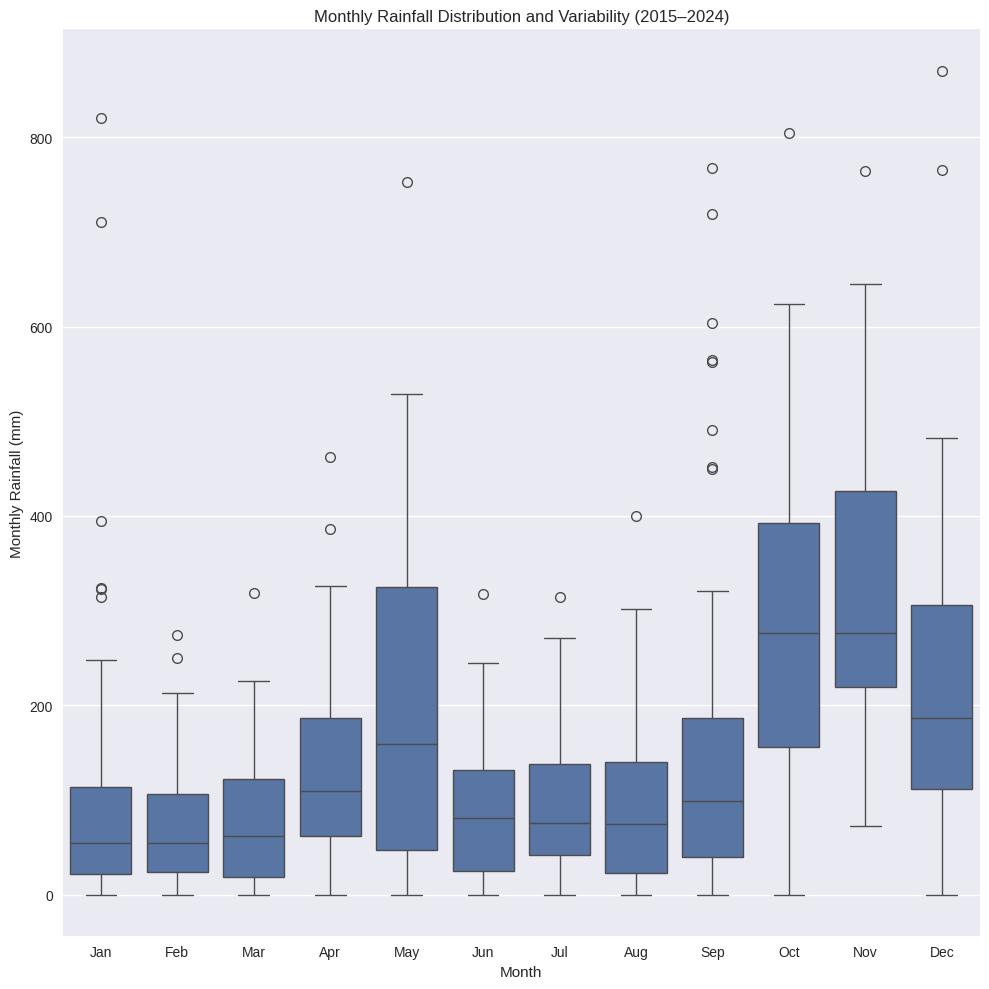

In [74]:
plt.figure(figsize=(10,10))

sns.boxplot(
    data=monthly_rainfall_long,
    x='month',
    y='prcp_total_mm',
    color='#4C72B0'
)

plt.xlabel('Month')
plt.ylabel('Monthly Rainfall (mm)')
plt.title('Monthly Rainfall Distribution and Variability (2015–2024)')
plt.xticks(range(0,12),
           ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])

plt.tight_layout()
plt.show()


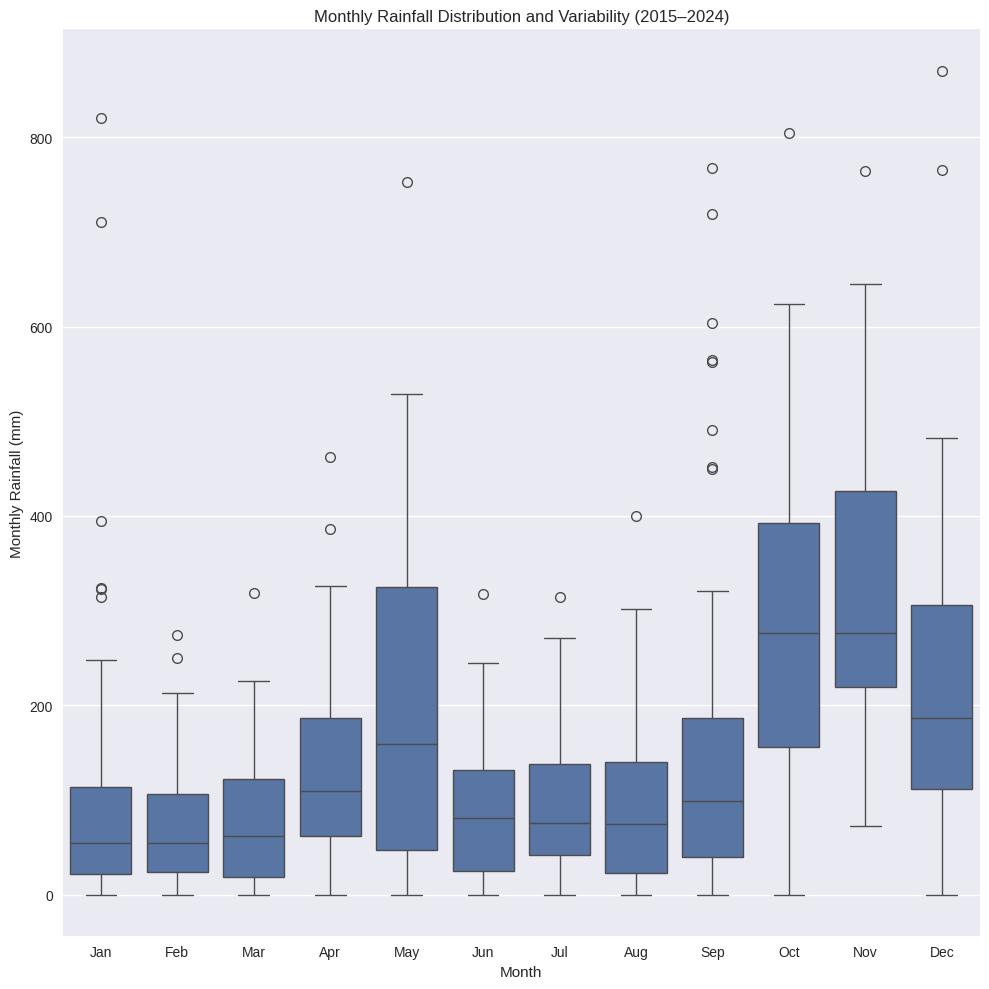

In [75]:
plt.figure(figsize=(10,10))

sns.boxplot(
    data=monthly_rainfall_long,
    x='month',
    y='prcp_total_mm',
    color='#4C72B0'
)

plt.xlabel('Month')
plt.ylabel('Monthly Rainfall (mm)')
plt.title('Monthly Rainfall Distribution and Variability (2015–2024)')

plt.xticks(range(0,12),
           ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])

plt.tight_layout()

# 🔹 Save HD image (publication quality)
plt.savefig(
    "monthly_rainfall_boxplot.png",
    dpi=300,              # 300 = journal quality
    bbox_inches='tight'
)

plt.show()

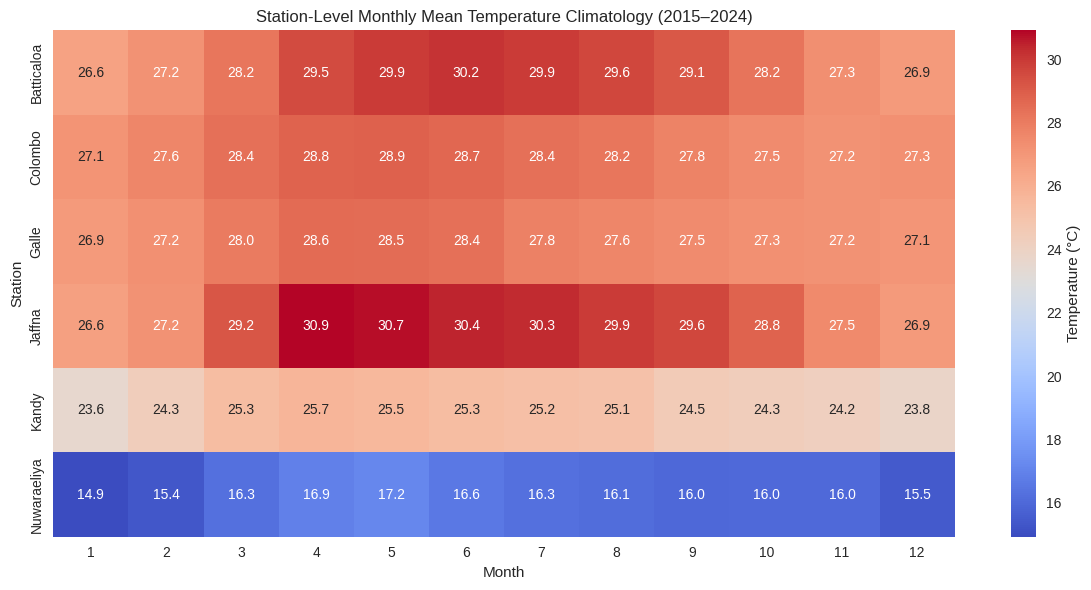

In [76]:
plt.figure(figsize=(12,6))

sns.heatmap(
    temp_climatology,
    annot=True,
    fmt='.1f',
    cmap='coolwarm',
    cbar_kws={'label': 'Temperature (°C)'}
)

plt.xlabel('Month')
plt.ylabel('Station')
plt.title('Station-Level Monthly Mean Temperature Climatology (2015–2024)')
plt.tight_layout()
plt.show()


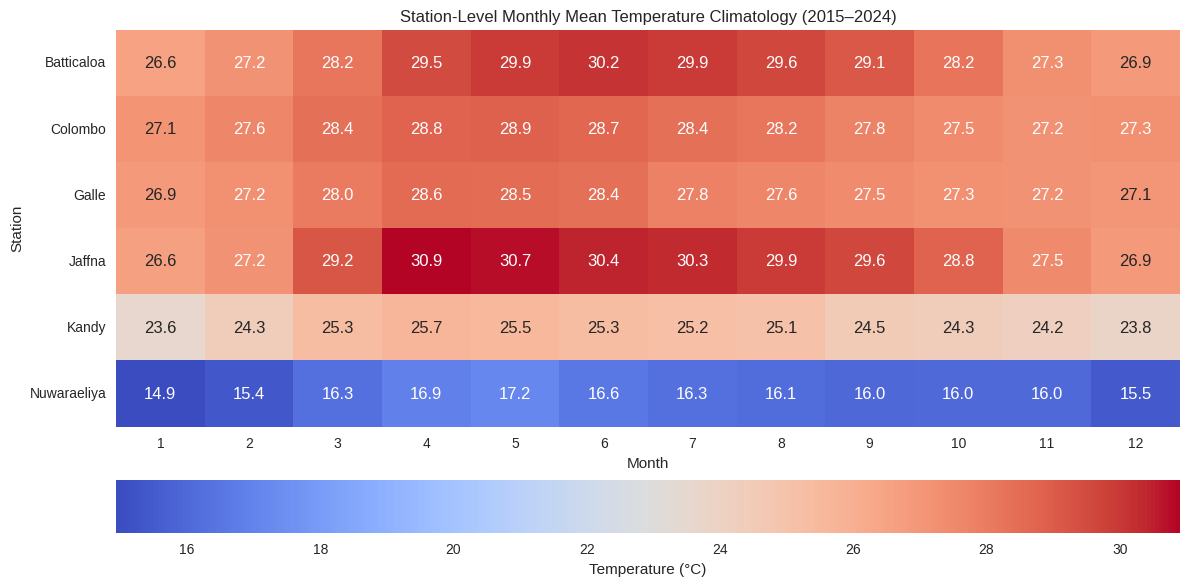

In [77]:
plt.figure(figsize=(12,6))

sns.heatmap(
    temp_climatology,
    annot=True,
    fmt='.1f',
    cmap='coolwarm',
    annot_kws={"size": 12},  # 🔹 Increase annotation font size
    cbar_kws={
        'label': 'Temperature (°C)',
        'orientation': 'horizontal',   # 🔹 Move legend to bottom
        'pad': 0.1                     # 🔹 Adjust spacing if needed
    }
)

plt.xlabel('Month')
plt.ylabel('Station')
plt.title('Station-Level Monthly Mean Temperature Climatology (2015–2024)')
plt.tight_layout()
plt.show()

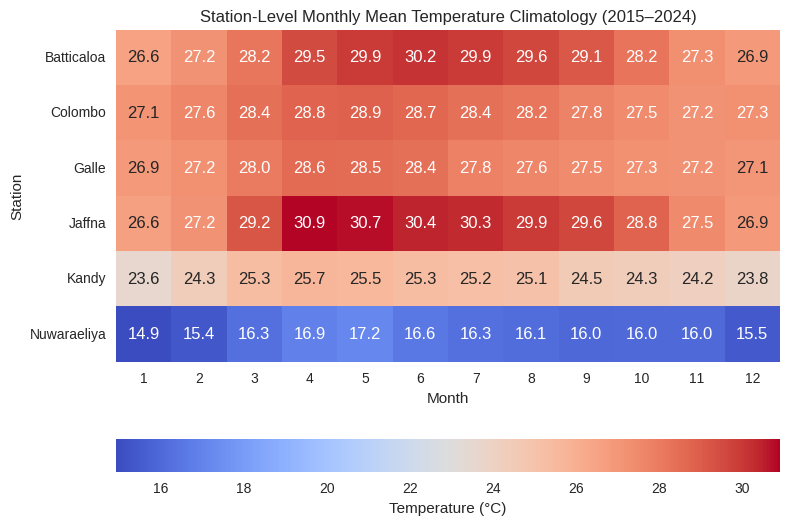

In [78]:
plt.figure(figsize=(8,8))  # 🔹 Square figure

sns.heatmap(
    temp_climatology,
    annot=True,
    fmt='.1f',
    cmap='coolwarm',
    square=True,  # 🔹 This makes each cell square
    annot_kws={"size": 12},
    cbar_kws={
        'label': 'Temperature (°C)',
        'orientation': 'horizontal',
        'pad': 0.1
    }
)

plt.xlabel('Month')
plt.ylabel('Station')
plt.title('Station-Level Monthly Mean Temperature Climatology (2015–2024)')
plt.tight_layout()
plt.show()

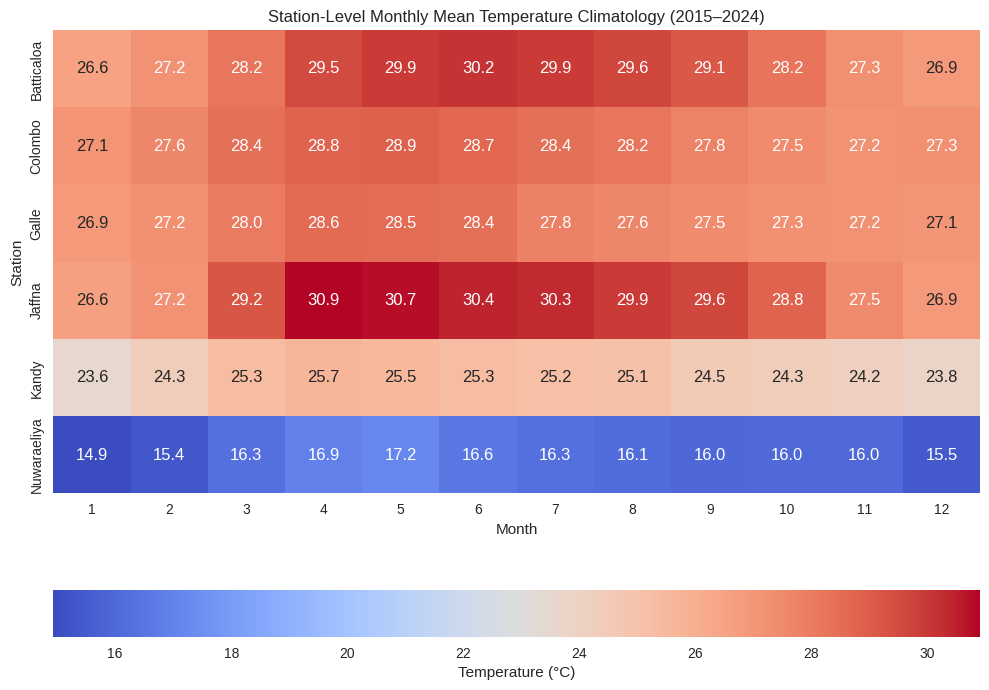

In [79]:
plt.figure(figsize=(10,10))

sns.heatmap(
    temp_climatology,
    annot=True,
    fmt='.1f',
    cmap='coolwarm',
    square=True,
    annot_kws={"size": 12},
    cbar_kws={
        'label': 'Temperature (°C)',
        'orientation': 'horizontal',
        'pad': 0.1
    }
)

plt.xlabel('Month')
plt.ylabel('Station')
plt.title('Station-Level Monthly Mean Temperature Climatology (2015–2024)')

plt.tight_layout()

# 🔹 Save as HD image
plt.savefig(
    "temperature_climatology_heatmap.png",
    dpi=300,              # 300 dpi = publication quality
    bbox_inches='tight'   # removes extra whitespace
)

plt.show()

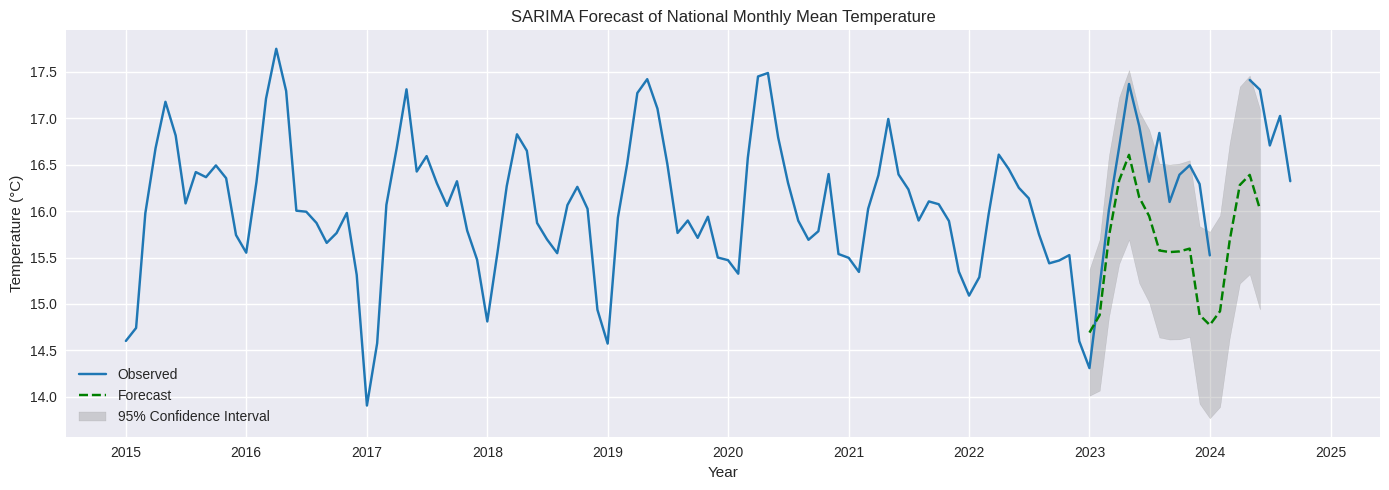

In [80]:
plt.figure(figsize=(14,5))

plt.plot(series.index, series, label='Observed', color='#1f77b4')

plt.plot(pred_mean.index, pred_mean,
         linestyle='--', color='green', label='Forecast')

plt.fill_between(
    conf_int.index,
    conf_int.iloc[:,0],
    conf_int.iloc[:,1],
    color='gray', alpha=0.3, label='95% Confidence Interval'
)

plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.title('SARIMA Forecast of National Monthly Mean Temperature')
plt.legend()
plt.tight_layout()
plt.show()


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

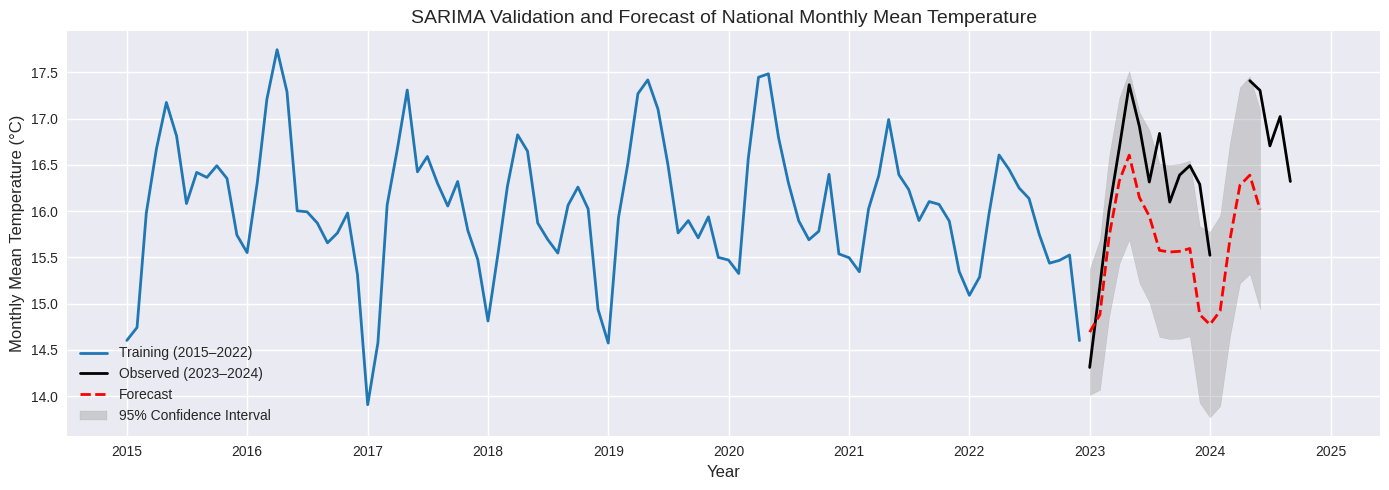

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

# Training data
plt.plot(train.index, train,
         label='Training (2015–2022)',
         color='#1f77b4', linewidth=2)

# Observed validation data
plt.plot(test.index, test,
         label='Observed (2023–2024)',
         color='black', linewidth=2)

# Forecast during validation
plt.plot(pred_mean.index, pred_mean,
         linestyle='--',
         color='red',
         linewidth=2,
         label='Forecast')

# Confidence interval
plt.fill_between(
    conf_int.index,
    conf_int.iloc[:,0],
    conf_int.iloc[:,1],
    color='gray',
    alpha=0.3,
    label='95% Confidence Interval'
)

plt.xlabel('Year', fontsize=12)
plt.ylabel('Monthly Mean Temperature (°C)', fontsize=12)
plt.title('SARIMA Validation and Forecast of National Monthly Mean Temperature', fontsize=14)
plt.legend()
plt.tight_layout()

plt.savefig(
    'sarima_validation_plot_hd.png',
    dpi=300,
    bbox_inches='tight'
)
from google.colab import files
files.download('sarima_validation_plot_hd.png')

plt.show()


In [81]:
# Drop NaNs from test
test_clean = test.dropna()

# Align on common timestamps
common_index = test_clean.index.intersection(pred_mean.index)

test_aligned = test_clean.loc[common_index]
pred_aligned = pred_mean.loc[common_index]

rmse = np.sqrt(mean_squared_error(test_aligned, pred_aligned))
mae  = mean_absolute_error(test_aligned, pred_aligned)

print(f"RMSE: {rmse:.3f} °C")
print(f"MAE : {mae:.3f} °C")
print(f"Validation months used: {len(common_index)}")



RMSE: 0.832 °C
MAE : 0.748 °C
Validation months used: 15


In [82]:
missing_in_forecast = test_clean.index.difference(pred_mean.index)
missing_in_forecast


DatetimeIndex(['2024-07-01', '2024-08-01', '2024-09-01', '2024-12-01'], dtype='datetime64[ns]', freq=None)

In [83]:
common_idx = test_s.index.intersection(pred_s.index)

rmse = np.sqrt(mean_squared_error(
    test_s.loc[common_idx],
    pred_s.loc[common_idx]
))

mae = mean_absolute_error(
    test_s.loc[common_idx],
    pred_s.loc[common_idx]
)


ValueError: Input contains NaN.

In [ ]:
station_metrics = []

for station, df_station in monthly_station.groupby('station'):
    series_s = (
        df_station
        .set_index('year_month')['temp_mean_c']
        .asfreq('MS')
        .dropna()
    )

    train_s = series_s[:'2022-12-01']
    test_s  = series_s['2023-01-01':'2024-12-01']

    if len(test_s) < 12:
        continue

    model_s = SARIMAX(
        train_s,
        order=(1,1,1),
        seasonal_order=(1,1,1,12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    res_s = model_s.fit(disp=False)
    pred_s = res_s.get_forecast(len(test_s)).predicted_mean
    pred_s.index = test_s.index

    station_metrics.append({
        'station': station,
        'RMSE': np.sqrt(mean_squared_error(test_s, pred_s)),
        'MAE': mean_absolute_error(test_s, pred_s)
    })

station_metrics_df = pd.DataFrame(station_metrics)
station_metrics_df
